<a href="https://colab.research.google.com/github/3B232056/2026_DL_hws/blob/main/hw4_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

匯入套件

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.layers import Dropout

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 625s 4us/step


#資料預處理

*  訓練/測試資料形狀





In [3]:
print("訓練資料筆數:", len(x_train))
print("測試資料筆數:", len(x_test))

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)

print("x_test:", x_test.shape)
print("y_test:", y_test.shape)


label_dict = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

訓練資料筆數: 50000
測試資料筆數: 10000
x_train: (50000, 32, 32, 3)
y_train: (50000, 1)
x_test: (10000, 32, 32, 3)
y_test: (10000, 1)


*  訓練資料圖片

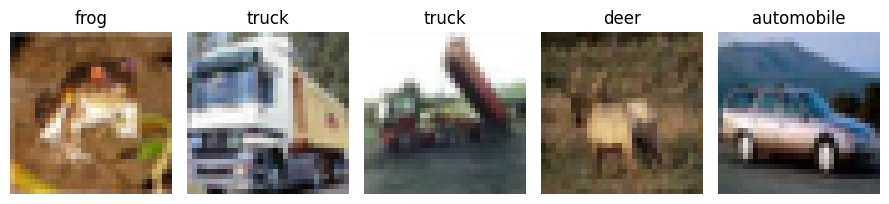

In [4]:
plt.figure(figsize=(9, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i])
    label_index = int(y_train[i][0])
    plt.title(label_dict[label_index])
    plt.axis("off")
plt.tight_layout()
plt.show()

*  拉平常模化、one-hot-encoding

In [5]:
x_train_normalize = x_train / 255
x_test_normalize = x_test / 255

y_train_OneHot = to_categorical(y_train, 10)
y_test_OneHot = to_categorical(y_test, 10)

In [6]:
print(x_train_normalize.shape)
print(x_test_normalize.shape)

print(y_train_OneHot.shape)
print(y_test_OneHot.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)
(50000, 10)
(10000, 10)


#建立神經網路模型

In [29]:
model = Sequential()

In [30]:
#第一層：卷積層，32 個 Filter，尺寸 (3,3)
model.add(Conv2D(32, (3, 3), padding='same',
                 input_shape=(32, 32, 3),
                 activation='relu'))

In [31]:
# 第二層
model.add(Dropout(0.3))


In [32]:
# 第三層：卷積層，32 個 Filter，尺寸 (3,3)
model.add(Conv2D(32, (3, 3), padding='same',
                 activation='relu'))

In [33]:
# 第四層：池化層，尺寸 (2,2)
model.add(MaxPool2D(pool_size=(2, 2)))

In [34]:
# 第五層:卷積層，64 個 Filter，尺寸大小為 (3, 3)
model.add(Conv2D(64, (3, 3), padding='same',
                 activation='relu'))

In [35]:
# 第六層
model.add(Dropout(0.3))

In [36]:
# 第七層:卷積層，64 個 Filter，尺寸大小為 (3, 3)
model.add(Conv2D(64, (3, 3), padding='same',
                 activation='relu'))

In [37]:
# 第八層：池化層，尺寸 (2,2)
model.add(MaxPool2D(pool_size=(2, 2)))

In [38]:
# 第九層：卷積層，128 個 Filter，尺寸大小為 (3, 3)
model.add(Conv2D(128, (3, 3), padding='same',
                 activation='relu'))

In [39]:
# 第十層
model.add(Dropout(0.3))

In [40]:
# 第十一層：卷積層，128 個 Filter，尺寸大小為 (3, 3)
model.add(Conv2D(128, (3, 3), padding='same',
                 activation='relu'))

In [41]:
# 第十二層：池化層，尺寸 (2,2)
model.add(MaxPool2D(pool_size=(2, 2)))

In [42]:
# 第十三層：拉平層
model.add(Flatten())

In [43]:
# 第十四層：
model.add(Dropout(0.3))

In [44]:
# 第十五層：全連接層
model.add(Dense(2500, activation='relu'))

In [45]:
# 第十六層：
model.add(Dropout(0.3))

In [46]:
# 第十七層：全連接層
model.add(Dense(1500, activation='relu'))

In [47]:
# 第十八層：
model.add(Dropout(0.3))

In [48]:
# 第十九層：全連接層
model.add(Dense(10,activation='softmax'))

In [49]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2500)           │     5,122,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 2500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1500)           │     3,751,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │        15,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,176,018 (35.00 MB)

 Trainable params: 9,176,018 (35.00 MB)

 Non-trainable params: 0 (0.00 B)

#每一層參數個數


*  第一層:(3×3×3+1)×32=896
*  第三層:(3×3×32+1)×32=9248
*  第五層:(3×3×32+1)×64=18496
*  第七層:(3×3×64+1)×64=36928
*  第九層:(3×3×64+1)×128=73856
*  第十一層:(3×3×128+1)×128=147584
*  Flatten後變成：:4×4×128=2048
*  第十五層:(2048+1)×2500=5122500
*  第十七層:(2500+1)×1500=3751500
*  最後全連接層:(1500 + 1) × 10 = 15010



#input shape及每一層的output shape
*  批次訓練時的input shape:(None, 32, 32, 3)
*  第一層output shape :(None, 32, 32, 32)
*  第二層output shape :(None, 32, 32, 32)
*  第三層output shape :(None, 32, 32, 32)
*  第四層output shape :(None, 16, 16, 32)
*  第五層output shape :(None, 16, 16, 64)
*  第六層output shape :(None, 16, 16, 64)
*  第七層output shape :(None, 16, 16, 64)
*  第八層output shape :(None, 8, 8, 64)
*  第九層output shape :(None, 8, 8, 128)
*  第十層output shape :(None, 8, 8, 128)
*  第十一層output shape :(None, 8, 8, 128)
*  第十二層output shape :(None, 4, 4, 128)
*  拉平層output shape :(None, 2048)
*  第十四層output shape :(None, 2048)
*  第十五層全連接層output shape :(None, 2500)   
*  第十六層output shape :(None, 2500)   
*  第十七層全連接層output shape :(None, 1500)
*  第十八層output shape :(None, 1500)  
*  第十九層全連接層output shape :(None, 10)

#訓練神經網路模型

In [50]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

In [51]:
train_history = model.fit(x=x_train_normalize,
              y=y_train_OneHot,
              validation_split=0.2,
              epochs=50,
              batch_size=128,
              verbose=2)

Epoch 1/50
313/313 - 54s - 172ms/step - accuracy: 0.3304 - loss: 1.7865 - val_accuracy: 0.4532 - val_loss: 1.4955
Epoch 2/50
313/313 - 5s - 17ms/step - accuracy: 0.5098 - loss: 1.3475 - val_accuracy: 0.5393 - val_loss: 1.2509
Epoch 3/50
313/313 - 5s - 17ms/step - accuracy: 0.5862 - loss: 1.1549 - val_accuracy: 0.6177 - val_loss: 1.0940
Epoch 4/50
313/313 - 6s - 18ms/step - accuracy: 0.6327 - loss: 1.0316 - val_accuracy: 0.6635 - val_loss: 0.9530
Epoch 5/50
313/313 - 5s - 17ms/step - accuracy: 0.6663 - loss: 0.9356 - val_accuracy: 0.7091 - val_loss: 0.8429
Epoch 6/50
313/313 - 5s - 17ms/step - accuracy: 0.6980 - loss: 0.8543 - val_accuracy: 0.7054 - val_loss: 0.8594
Epoch 7/50
313/313 - 5s - 17ms/step - accuracy: 0.7194 - loss: 0.7928 - val_accuracy: 0.7341 - val_loss: 0.7660
Epoch 8/50
313/313 - 5s - 16ms/step - accuracy: 0.7410 - loss: 0.7309 - val_accuracy: 0.7426 - val_loss: 0.7431
Epoch 9/50
313/313 - 5s - 17ms/step - accuracy: 0.7534 - loss: 0.6954 - val_accuracy: 0.7303 - val_los

#input shape及每一層的output shape
*  批次訓練時的input shape:(128, 32, 32, 3)
*  第一層output shape :(128, 32, 32, 32)
*  第二層output shape :(128, 32, 32, 32)
*  第三層output shape :(128, 32, 32, 32)
*  第四層output shape :(128, 16, 16, 32)
*  第五層output shape :(128, 16, 16, 64)
*  第六層output shape :(128, 16, 16, 64)
*  第七層output shape :(128, 16, 16, 64)
*  第八層output shape :(128, 8, 8, 64)
*  第九層output shape :(128, 8, 8, 128)
*  第十層output shape :(128, 8, 8, 128)
*  第十一層output shape :(128, 8, 8, 128)
*  第十二層output shape :(128, 4, 4, 128)
*  拉平層output shape :(128, 2048)
*  第十四層output shape :(128, 2048)
*  第十五層全連接層output shape :(128, 2500)   
*  第十六層output shape :(128, 2500)   
*  第十七層全連接層output shape :(128, 1500)
*  第十八層output shape :(128, 1500)  
*  第十九層全連接層output shape :(128, 10)

In [52]:
def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

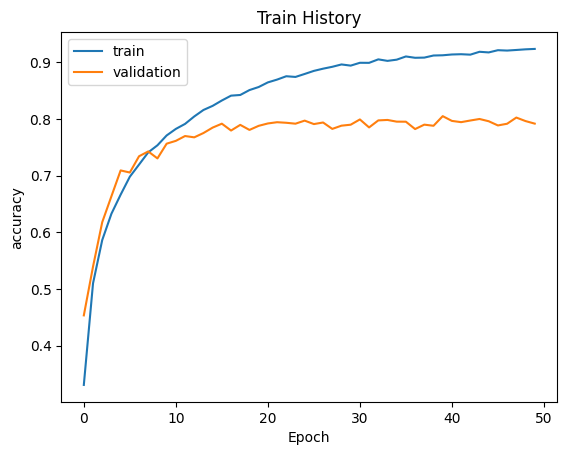

In [53]:
show_train_history(train_history,'accuracy','val_accuracy')

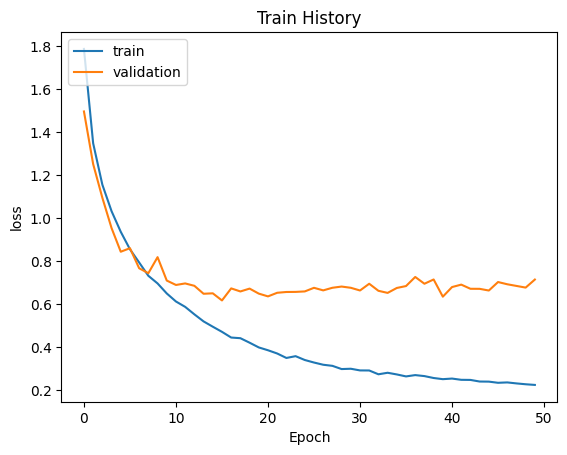

In [54]:
show_train_history(train_history,'loss','val_loss')

#結果:這兩張圖有輕微過度擬合的現象

#評估模型準確率

In [55]:
scores = model.evaluate(x_test_normalize,y_test_OneHot)

print("Loss =", scores[0])
print("正確率 =", scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7896 - loss: 0.7495
Loss = 0.7494935393333435
正確率 = 0.7896000146865845


#hw4-2跟hw4-3比較結果

* hw4-2

  2個卷積區塊

  全連接層1024個神經元

  Epochs=20，回合數較少，訓練較快

  參數較少

  驗證準確率約72%

  

* hw4-3

  6個卷積層

  全連接層增加2500/1500個神經元

  最大 Filter 增加到 128，強化特徵擷取能力

  驗證準確率提高(原本0.72提升至0.79)

  參數數量增加，模型複雜度遠高於 hw4-2

  訓練後期 Validation Loss 有回升趨勢，顯示模型出現過度擬合現象


* 結論:整體分類效果優於 hw4-2，hw4-3透過增加卷積層數、Filter數量及全連接層神經元，提高模型的特徵擷取能力，使驗證準確率由72%提升至79%，。然而模型複雜度與訓練時間也明顯增加，且出現過度擬合現象。

#進行預測

In [56]:
y_pred_prob = model.predict(x_test_normalize)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test_OneHot, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


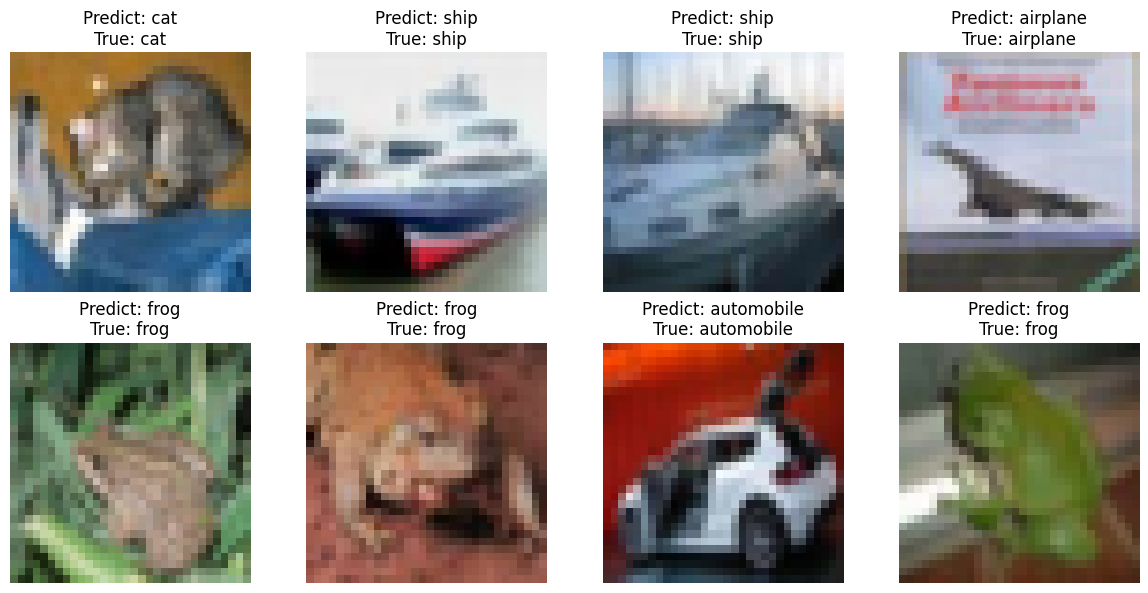

In [57]:
# 顯示 8 張測試圖片；標題為標籤名稱
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x_test[i])
    plt.title(
        f"Predict: {label_dict[y_pred[i]]}\n"
        f"True: {label_dict[y_true[i]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

#以混淆矩陣(Confusion matrix)呈現預測結果

In [58]:
cm = pd.crosstab(y_true,y_pred,rownames=['label'],colnames=['predict'])
print(cm)

predict    0    1    2    3    4    5    6    7    8    9
label                                                    
0        823   10   30   32   15    6   14   11   41   18
1         11  895    1   16    3    5    8    2   10   49
2         52    1  668   66   89   44   62   11    7    0
3          9    1   45  691   45  115   62   27    2    3
4         14    1   28   80  789   17   37   30    1    3
5          4    1   25  205   25  678   24   33    2    3
6          3    1   26   66   28   24  844    4    2    2
7         10    0   23   55   56   33    6  812    2    3
8         55   17    7   31    5    9    8    2  845   21
9         23   59    5   33    4    3    4    8   10  851


In [59]:
# 建立 DataFrame
df = pd.DataFrame({
    'label': y_true,
    'predict': y_pred
})

# 顯示前 10 筆測試資料
df[:10]

,label,predict
0,3,3
1,8,8
2,8,8
3,0,0
4,6,6
5,6,6
6,1,1
7,6,6
8,3,3
9,1,9


In [60]:
df[(df.label==4)&(df.predict==1)]  # 真實標籤為4，卻預測為1

,label,predict
1049,4,1


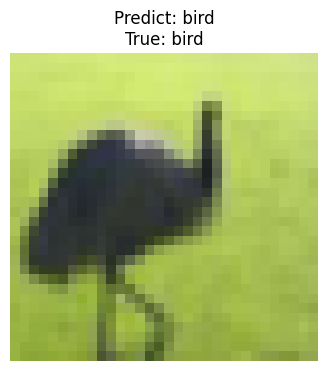

In [61]:
#預測正確
idx = 123

plt.figure(figsize=(4,4))
plt.imshow(x_test[idx])

plt.title(
    f"Predict: {label_dict[y_pred[idx]]}\n"
    f"True: {label_dict[y_true[idx]]}"
)

plt.axis("off")
plt.show()

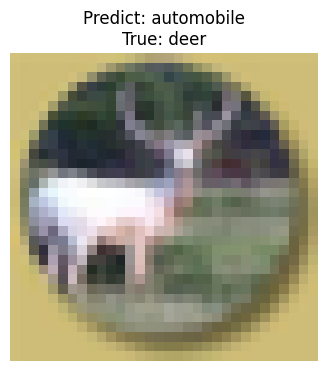

In [69]:
#預測錯誤
idx = 1049

plt.figure(figsize=(4,4))
plt.imshow(x_test[idx])

plt.title(
    f"Predict: {label_dict[y_pred[idx]]}\n"
    f"True: {label_dict[y_true[idx]]}"
)

plt.axis("off")
plt.show()

#儲存完整模型

In [70]:
#儲存 model
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [71]:
%cd '/content/drive/My Drive/Colab Notebooks'

/content/drive/My Drive/Colab Notebooks


In [72]:
model.save('my_cnn_model_hw4-3.keras')

#interact_manual

In [73]:
from ipywidgets import interact_manual

In [74]:
def test(測試編號):

    plt.figure(figsize=(4,4))
    plt.imshow(x_test[測試編號])
    plt.axis('off')
    plt.show()

    pred_class = y_pred[測試編號]
    actual_class = y_true[測試編號]

    print('神經網路判斷為:',
          label_dict[pred_class],
          f'({pred_class})')

    print('實際答案為:',
          label_dict[actual_class],
          f'({actual_class})')

interact_manual(test, 測試編號=(0,9999))

interactive(children=(IntSlider(value=4999, description='測試編號', max=9999), Button(description='Run Interact', …

<function __main__.test(測試編號)>